In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/student-mat.csv", sep=";")

features = [
    "age", "Medu", "Fedu", "traveltime",
    "studytime", "failures", "famrel",
    "freetime", "goout", "Dalc", "Walc",
    "health", "absences"
]

X = df[features]
y = (df["G3"] >= 10).astype(int)

print("Total students:", len(df))
print("\nClass distribution:")
print(y.map({0: "Fail", 1: "Pass"}).value_counts())

Total students: 395

Class distribution:
G3
Pass    265
Fail    130
Name: count, dtype: int64


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced",max_iter=1000)
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

y_pred = model.predict(X_test)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.3f}")

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Fail", "Pass"],
    zero_division=0
))

Accuracy:  0.633
Precision: 0.750
Recall:    0.679
F1-score:  0.713

Classification report:
              precision    recall  f1-score   support

        Fail       0.45      0.54      0.49        26
        Pass       0.75      0.68      0.71        53

    accuracy                           0.63        79
   macro avg       0.60      0.61      0.60        79
weighted avg       0.65      0.63      0.64        79



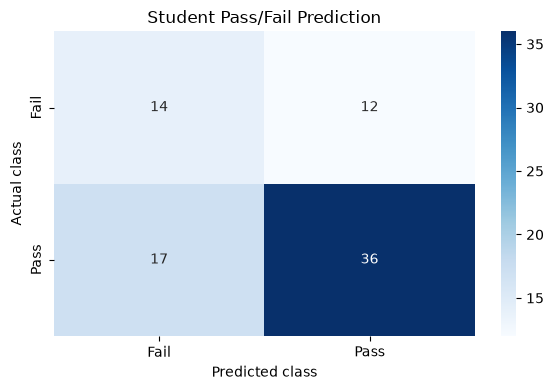

In [7]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fail", "Pass"],
    yticklabels=["Fail", "Pass"]
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Student Pass/Fail Prediction")
plt.tight_layout()
plt.show()